# **Preprocessing Text**

#Scrapping from Play Store

In [ ]:
import warnings
warnings.filterwarnings(action='ignore')

!pip install google-play-scraper demoji nltk wordcloud matplotlib Levenshtein
!pip install --upgrade git+https://github.com/ariaghora/mpstemmer.git


import json
import re
import string
import demoji
import nltk
import pandas as pd
import matplotlib.pyplot as plt
from wordcloud import WordCloud
from google_play_scraper import Sort, reviews
from mpstemmer import MPStemmer
from nltk.corpus import stopwords

nltk.download('stopwords')

  Cloning https://github.com/ariaghora/mpstemmer.git to /tmp/pip-req-build-m8wkqr53
  Running command git clone --filter=blob:none --quiet https://github.com/ariaghora/mpstemmer.git /tmp/pip-req-build-m8wkqr53
  Resolved https://github.com/ariaghora/mpstemmer.git to commit 25a5fd923af163a7eac3a5ec976984156ca8fa8b
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [ ]:
# Scraping ulasan Mobile Legends dari Play Store
result, _ = reviews(
    'com.mobile.legends',
    lang='en',
    country='Us',
    sort=Sort.NEWEST,
    count=100
)

with open("response.json", "w", encoding='utf-8') as f:
    json.dump(result, f, indent=4, ensure_ascii=False, default=str)

In [ ]:
!pip install langdetect

In [ ]:
import json
import pandas as pd
from langdetect import detect


with open("response.json", "r", encoding='utf-8') as f:
    data = json.load(f)

authors = []
comments = []

for item in data:
    text = item["content"]
    try:

        if detect(text) == 'en':
            authors.append(item["userName"])
            comments.append(text)
    except:
        pass

df = pd.DataFrame({'Authors': authors, 'Comments': comments})
df.rename(columns={'Comments': 'text'}, inplace=True)
df

,Authors,text
0,billy joe ojeda,"moontoon, outsmarted player must be with the o..."
1,karl,Mobile Legends: Bang Bang has several problems...
2,Jay Mark,this game is the worse
3,Ljourn Español (LJ),I keep on having AI teammates and causes for m...
4,MALVIN MARTIN,This game is not fun. This game is not like th...
5,Joseph Rada,im experiencing lag consistently even though i...
6,Bee Bop,Nerf or remove sky piercer from the game.
7,John Michael Villena,The new update is suck i can't move my hero an...
8,MD Masud,truly one of the best mobile phone games I've ...
9,Nicholas FOO,matchmaking is super unfair and makes the game...


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 43 entries, 0 to 42
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   Authors  43 non-null     object
 1   text     43 non-null     object
dtypes: object(2)
memory usage: 820.0+ bytes


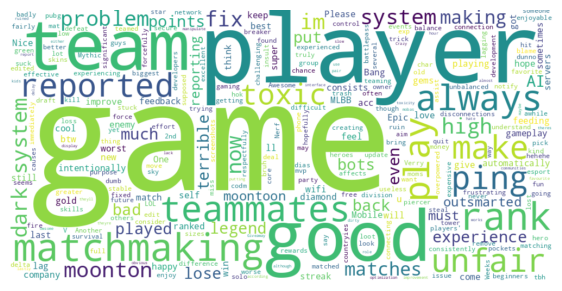

In [ ]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

text = ' '.join(df['text'].dropna().astype(str))

wordcloud = WordCloud(width=1000, height=500, background_color='white', max_words=1000).generate(text)

plt.figure(figsize=(7, 4))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.show()

In [ ]:
import re
import string
import demoji
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer # Mengganti MPStemmer dengan PorterStemmer

nltk.download('stopwords')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [ ]:
# ini fungsinya untuk mengRemove HTML ya (khan,rin)
def remove_html(text):
    html_pattern = re.compile('<.*?>')
    return html_pattern.sub(r'', text)

In [ ]:
#  menghapus Hashtag
def remove_hashtag(text):
    return re.sub(r'#\w+', '', text)

In [ ]:
 #Remove Links & Email
def remove_rls(text):
    text = re.sub(r'https?://\S+', '', str(text))
    text = re.sub(r'http\S+', '', str(text))
    text = re.sub(r'www\S+', '', str(text))
    text = re.sub(r'\S+@\S+', '', str(text))
    return text

In [ ]:
#  Remove Punctuation(ngehapus simbol simbol dan emotikon yang pake simbol ) List & Emoticon Teks
def remove_punctuation_list(text):
    text = re.sub(r'(:\)|:-\)|:D|:-D|;\)|;-\))', '', text)
    text = re.sub(r'(:\(|:-\()', '', text)
    text = re.sub(r'(:v|:-v)', '', text)
    text = re.sub(r'[!"#$%&\'()*+,\-./:;<=>?@\[\]^_`{|}~]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

In [ ]:
def remove_emoji(text):
    cleaned_text = demoji.replace(text, repl="")
    cleaned_text = re.sub(r'[^\x00-\x7F]+', '', cleaned_text)
    return cleaned_text

In [ ]:
# Inisialisasi PorterStemmer untuk Bahasa Inggris
ps = PorterStemmer()


In [ ]:
# Stopwords Bahasa Inggris
sw_english = set(stopwords.words('english')) - {'not', 'no', 'nor', 'neither'}

def remove_stopwords(text):
    return " ".join([word for word in str(text).split() if word not in sw_english])

In [ ]:
df['rm_html'] = df['text'].apply(remove_html)
df.head(20)

,Authors,text,rm_html
0,billy joe ojeda,"moontoon, outsmarted player must be with the o...","moontoon, outsmarted player must be with the o..."
1,karl,Mobile Legends: Bang Bang has several problems...,Mobile Legends: Bang Bang has several problems...
2,Jay Mark,this game is the worse,this game is the worse
3,Ljourn Español (LJ),I keep on having AI teammates and causes for m...,I keep on having AI teammates and causes for m...
4,MALVIN MARTIN,This game is not fun. This game is not like th...,This game is not fun. This game is not like th...
5,Joseph Rada,im experiencing lag consistently even though i...,im experiencing lag consistently even though i...
6,Bee Bop,Nerf or remove sky piercer from the game.,Nerf or remove sky piercer from the game.
7,John Michael Villena,The new update is suck i can't move my hero an...,The new update is suck i can't move my hero an...
8,MD Masud,truly one of the best mobile phone games I've ...,truly one of the best mobile phone games I've ...
9,Nicholas FOO,matchmaking is super unfair and makes the game...,matchmaking is super unfair and makes the game...


In [ ]:
df['rm_hashtag'] = df['rm_html'].apply(remove_hashtag)
df[['rm_html','rm_hashtag']].head(20)

,rm_html,rm_hashtag
0,"moontoon, outsmarted player must be with the o...","moontoon, outsmarted player must be with the o..."
1,Mobile Legends: Bang Bang has several problems...,Mobile Legends: Bang Bang has several problems...
2,this game is the worse,this game is the worse
3,I keep on having AI teammates and causes for m...,I keep on having AI teammates and causes for m...
4,This game is not fun. This game is not like th...,This game is not fun. This game is not like th...
5,im experiencing lag consistently even though i...,im experiencing lag consistently even though i...
6,Nerf or remove sky piercer from the game.,Nerf or remove sky piercer from the game.
7,The new update is suck i can't move my hero an...,The new update is suck i can't move my hero an...
8,truly one of the best mobile phone games I've ...,truly one of the best mobile phone games I've ...
9,matchmaking is super unfair and makes the game...,matchmaking is super unfair and makes the game...


In [ ]:
df['lower_case'] = df['rm_hashtag'].str.lower()
df[['rm_hashtag', 'lower_case']].head(20)

,rm_hashtag,lower_case
0,"moontoon, outsmarted player must be with the o...","moontoon, outsmarted player must be with the o..."
1,Mobile Legends: Bang Bang has several problems...,mobile legends: bang bang has several problems...
2,this game is the worse,this game is the worse
3,I keep on having AI teammates and causes for m...,i keep on having ai teammates and causes for m...
4,This game is not fun. This game is not like th...,this game is not fun. this game is not like th...
5,im experiencing lag consistently even though i...,im experiencing lag consistently even though i...
6,Nerf or remove sky piercer from the game.,nerf or remove sky piercer from the game.
7,The new update is suck i can't move my hero an...,the new update is suck i can't move my hero an...
8,truly one of the best mobile phone games I've ...,truly one of the best mobile phone games i've ...
9,matchmaking is super unfair and makes the game...,matchmaking is super unfair and makes the game...


In [ ]:
df['rm_url'] = df['lower_case'].apply(remove_rls)
df[['lower_case','rm_url']].head(20)

,lower_case,rm_url
0,"moontoon, outsmarted player must be with the o...","moontoon, outsmarted player must be with the o..."
1,mobile legends: bang bang has several problems...,mobile legends: bang bang has several problems...
2,this game is the worse,this game is the worse
3,i keep on having ai teammates and causes for m...,i keep on having ai teammates and causes for m...
4,this game is not fun. this game is not like th...,this game is not fun. this game is not like th...
5,im experiencing lag consistently even though i...,im experiencing lag consistently even though i...
6,nerf or remove sky piercer from the game.,nerf or remove sky piercer from the game.
7,the new update is suck i can't move my hero an...,the new update is suck i can't move my hero an...
8,truly one of the best mobile phone games i've ...,truly one of the best mobile phone games i've ...
9,matchmaking is super unfair and makes the game...,matchmaking is super unfair and makes the game...


In [ ]:
df['rm_punc'] = df['rm_url'].apply(remove_punctuation_list)
df[['rm_url','rm_punc']].head(20)

,rm_url,rm_punc
0,"moontoon, outsmarted player must be with the o...",moontoon outsmarted player must be with the ou...
1,mobile legends: bang bang has several problems...,mobile legends bang bang has several problems ...
2,this game is the worse,this game is the worse
3,i keep on having ai teammates and causes for m...,i keep on having ai teammates and causes for m...
4,this game is not fun. this game is not like th...,this game is not fun this game is not like the...
5,im experiencing lag consistently even though i...,im experiencing lag consistently even though i...
6,nerf or remove sky piercer from the game.,nerf or remove sky piercer from the game
7,the new update is suck i can't move my hero an...,the new update is suck i can t move my hero an...
8,truly one of the best mobile phone games i've ...,truly one of the best mobile phone games i ve ...
9,matchmaking is super unfair and makes the game...,matchmaking is super unfair and makes the game...


In [ ]:
df['rm_stopwords'] = df['rm_punc'].apply(lambda x: " ".join([ps.stem(word) for word in str(x).split()]) if isinstance(x, str) else '')
df[['rm_punc','rm_stopwords']].head(20)


,rm_punc,rm_stopwords
0,moontoon outsmarted player must be with the ou...,moontoon outsmart player must be with the outs...
1,mobile legends bang bang has several problems ...,mobil legend bang bang ha sever problem that c...
2,this game is the worse,thi game is the wors
3,i keep on having ai teammates and causes for m...,i keep on have ai teammat and caus for me to l...
4,this game is not fun this game is not like the...,thi game is not fun thi game is not like the o...
5,im experiencing lag consistently even though i...,im experienc lag consist even though i have a ...
6,nerf or remove sky piercer from the game,nerf or remov sky piercer from the game
7,the new update is suck i can t move my hero an...,the new updat is suck i can t move my hero and...
8,truly one of the best mobile phone games i ve ...,truli one of the best mobil phone game i ve ev...
9,matchmaking is super unfair and makes the game...,matchmak is super unfair and make the game not...


In [ ]:
df.columns.tolist()

['Authors',
 'text',
 'rm_html',
 'rm_hashtag',
 'lower_case',
 'rm_url',
 'rm_punc',
 'rm_stopwords']

In [ ]:
df[['text',
    'rm_html',
    'rm_hashtag',
    'lower_case',
    'rm_url',
    'rm_punc',
    'rm_stopwords']].head()

,text,rm_html,rm_hashtag,lower_case,rm_url,rm_punc,rm_stopwords
0,"moontoon, outsmarted player must be with the o...","moontoon, outsmarted player must be with the o...","moontoon, outsmarted player must be with the o...","moontoon, outsmarted player must be with the o...","moontoon, outsmarted player must be with the o...",moontoon outsmarted player must be with the ou...,moontoon outsmart player must be with the outs...
1,Mobile Legends: Bang Bang has several problems...,Mobile Legends: Bang Bang has several problems...,Mobile Legends: Bang Bang has several problems...,mobile legends: bang bang has several problems...,mobile legends: bang bang has several problems...,mobile legends bang bang has several problems ...,mobil legend bang bang ha sever problem that c...
2,this game is the worse,this game is the worse,this game is the worse,this game is the worse,this game is the worse,this game is the worse,thi game is the wors
3,I keep on having AI teammates and causes for m...,I keep on having AI teammates and causes for m...,I keep on having AI teammates and causes for m...,i keep on having ai teammates and causes for m...,i keep on having ai teammates and causes for m...,i keep on having ai teammates and causes for m...,i keep on have ai teammat and caus for me to l...
4,This game is not fun. This game is not like th...,This game is not fun. This game is not like th...,This game is not fun. This game is not like th...,this game is not fun. this game is not like th...,this game is not fun. this game is not like th...,this game is not fun this game is not like the...,thi game is not fun thi game is not like the o...


In [ ]:



df['rm_punc'] = df['rm_url'].apply(remove_punctuation_list)

df['rm_stopwords'] = df['rm_punc'].apply(remove_stopwords)

df['rm_emoji'] = df['rm_stopwords'].apply(remove_emoji)

df[['rm_stopwords', 'rm_emoji']].head(20)




,rm_stopwords,rm_emoji
0,moontoon outsmarted player must outsmarted pla...,moontoon outsmarted player must outsmarted pla...
1,mobile legends bang bang several problems make...,mobile legends bang bang several problems make...
2,game worse,game worse
3,keep ai teammates causes lose game ai player c...,keep ai teammates causes lose game ai player c...
4,game not fun game not like game group division...,game not fun game not like game group division...
5,im experiencing lag consistently even though g...,im experiencing lag consistently even though g...
6,nerf remove sky piercer game,nerf remove sky piercer game
7,new update suck move hero also come back autom...,new update suck move hero also come back autom...
8,truly one best mobile phone games ever played ❤️,truly one best mobile phone games ever played
9,matchmaking super unfair makes game not enjoya...,matchmaking super unfair makes game not enjoya...


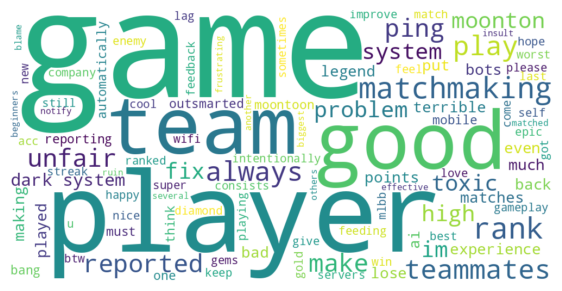

In [ ]:
text = ' '.join(df['rm_stopwords'].dropna().astype(str))

wordcloud = WordCloud(width=1000, height=500, background_color='white', max_words=100).generate(text)

plt.figure(figsize=(7, 4))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.show()

In [ ]:
df.rename(columns={'rm_stopwords': 'prepro'}, inplace=True)
df.info()

# Menyimpan hasil akhir ke file CSV (Sama persis seperti contoh dosen)
df[['Authors','text','prepro']].to_csv('mobile_legends_preprocessed.csv', index=False)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 43 entries, 0 to 42
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Authors     43 non-null     object
 1   text        43 non-null     object
 2   rm_html     43 non-null     object
 3   rm_hashtag  43 non-null     object
 4   lower_case  43 non-null     object
 5   rm_url      43 non-null     object
 6   rm_punc     43 non-null     object
 7   prepro      43 non-null     object
 8   rm_emoji    43 non-null     object
dtypes: object(9)
memory usage: 3.2+ KB


In [ ]:
# 1. Install dependensi yang kurang agar pemrosesan data bisa berjalan
!pip install langdetect

# 2. Re-create DataFrame dari file hasil scraping response.json
import json
import pandas as pd
from langdetect import detect

with open("response.json", "r", encoding='utf-8') as f:
    data = json.load(f)

authors = []
comments = []
for item in data:
    text = item["content"]
    try:
        if detect(text) == 'en':
            authors.append(item["userName"])
            comments.append(text)
    except:
        pass

df = pd.DataFrame({'Authors': authors, 'text': comments})

# Jalankan fungsi preprocessing minimal untuk menghasilkan kolom 'prepro'
# karena cell-cell preprocessing Anda bergantung pada df ini
from nltk.corpus import stopwords
import demoji
import re

sw_english = set(stopwords.words('english')) - {'not', 'no', 'nor', 'neither'}
def remove_stopwords(t):
    return " ".join([word for word in str(t).split() if word not in sw_english])

def remove_emoji(t):
    return re.sub(r'[^\x00-\x7F]+', '', demoji.replace(t, repl=""))

df['prepro'] = df['text'].str.lower().apply(remove_stopwords).apply(remove_emoji)

# 3. Simpan DataFrame tersebut menjadi file CSV di workspace Google Colab
df[['Authors', 'text', 'prepro']].to_csv('mobile_legends_preprocessed.csv', index=False)
print("File 'mobile_legends_preprocessed.csv' berhasil disimpan di workspace Colab!")

# 4. Download file CSV langsung ke komputer Anda
from google.colab import files
files.download('mobile_legends_preprocessed.csv')

File 'mobile_legends_preprocessed.csv' berhasil disimpan di workspace Colab!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# **Feature Engineering**

In [ ]:
#Try

!pip install scikit-learn gensim pandas numpy
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from gensim.models import Word2Vec, FastText

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 4.6 MB/s  0:00:06


In [ ]:
dokumen = [
    "data science itu seru dan menantang",
    "beljar data science butuh waktu dan usaha",
    "machine learning adalah bagian dari data science",
    "saya suka belajar machine learning setiap hari",
]

vocab = set()
for doc in dokumen:
  for word in doc.split():
    vocab.add(word)
    word2idx = {word: idx for idx, word in enumerate(vocab)}

def one_hot(kata):
  one_hot_kata = np.zeros(len(vocab))
  one_hot_kata[word2idx[kata]]
  return one_hot_kata

  pass

In [ ]:
vectorizer = CountVectorizer(binary=False)
X = vectorizer.fit_transform(dokumen)
df = pd.DataFrame(X.toarray(), columns=vectorizer.get_feature_names_out())
df

,adalah,bagian,belajar,beljar,butuh,dan,dari,data,hari,itu,learning,machine,menantang,saya,science,seru,setiap,suka,usaha,waktu
0,0,0,0,0,0,1,0,1,0,1,0,0,1,0,1,1,0,0,0,0
1,0,0,0,1,1,1,0,1,0,0,0,0,0,0,1,0,0,0,1,1
2,1,1,0,0,0,0,1,1,0,0,1,1,0,0,1,0,0,0,0,0
3,0,0,1,0,0,0,0,0,1,0,1,1,0,1,0,0,1,1,0,0


In [ ]:
!pip install gensim
import pandas as pd, numpy as np
from collections import Counter
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from gensim.models import Word2Vec, FastText

# Membaca data - pastikan file 'ulasan_clean.csv' atau file hasil preprocessing Anda ada di direktori kerja
# Jika nama filennya 'mobile_legends_preprocessed.csv', Anda bisa menyesuaikannya di sini.
try:
    df = pd.read_csv("ulasan_clean.csv").dropna(subset=["ulasan_clean"])
except FileNotFoundError:
    # fallback jika filenya bernama mobile_legends_preprocessed.csv
    df = pd.read_csv("mobile_legends_preprocessed.csv").dropna(subset=["prepro"])
    df.rename(columns={"prepro": "ulasan_clean"}, inplace=True)

df["ulasan_clean"] = df["ulasan_clean"].astype(str)

# One-Hot (kata)
vocab = sorted(set(w for s in df["ulasan_clean"] for w in s.split()))
idx = {w: i for i, w in enumerate(vocab)}
def one_hot(w):
    v = np.zeros(len(vocab)); v[idx[w]] = 1
    return v

# BoW dan TF-IDF
bow = CountVectorizer(max_features=1000).fit_transform(df["ulasan_clean"])
tfidf = TfidfVectorizer(max_features=1000).fit_transform(df["ulasan_clean"])

# Word2Vec: sg=0 CBOW, sg=1 Skip-gram
tokens = [s.split() for s in df["ulasan_clean"]]
cbow = Word2Vec(tokens, vector_size=100, window=5, min_count=2, sg=0)
skip = Word2Vec(tokens, vector_size=100, window=5, min_count=2, sg=1)

# Mencari kata terdekat (menggunakan kata yang ada dalam kosakata Anda)
try:
    print(skip.wv.most_similar("game"))
except KeyError:
    # Fallback jika kata 'game' tidak ada di kosakata Anda yang minim
    if len(skip.wv) > 0:
        print(skip.wv.most_similar(skip.wv.index_to_key[0]))

# FastText: bisa membuat vektor kata yang tidak ada di vocab
ft = FastText(tokens, vector_size=100, window=5, min_count=2, sg=1)
print(ft.wv["game"][:5])

[('new', 0.31170976161956787), ('system', 0.2364051640033722), ('get', 0.23297983407974243), ('bad', 0.20831653475761414), ('makes', 0.20553621649742126), ('last', 0.1831800937652588), ('happy', 0.17472369968891144), ('played', 0.17016731202602386), ('gems', 0.16116033494472504), ('ai', 0.15539558231830597)]
[ 0.00119331  0.00162208 -0.00131399 -0.00020559 -0.00081349]


# **TEXT SIMILARITY**

In [39]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity


Pada bagian ini kita mengimpor library yang akan digunakan. TfidfVectorizer "berfungsi mengubah teks menjadi data yang bisa dibaca komputer", sedangkan cosine_similarity digunakan" untuk menghitung tingkat kemiripan antar ulasan".

In [44]:
tfidf = TfidfVectorizer()

tfidf_matrix = tfidf.fit_transform(df['ulasan_clean'])

similarity_matrix = cosine_similarity(tfidf_matrix)

Pada tahap ini, ulasan yang sudah dibersihkan diubah menjadi angka agar dapat diproses oleh komputer. Setelah itu dilakukan perhitungan untuk mengetahui tingkat kemiripan antar ulasan.

In [45]:
print(similarity_matrix.shape)

(41, 41)


Kode ini digunakan untuk melihat jumlah data yang dibandingkan. Hasil (41,41) menunjukkan bahwa terdapat 41 ulasan yang dibandingkan satu sama lain.

In [46]:
import pandas as pd

sim_df = pd.DataFrame(similarity_matrix)

sim_df.iloc[:10, :10]

,0,1,2,3,4,5,6,7,8,9
0,1.000000,0.024899,0.027983,0.070703,0.102360,0.000000,0.014725,0.038135,0.000000,0.062096
1,0.024899,1.000000,0.041375,0.072183,0.044025,0.039894,0.021771,0.041667,0.091744,0.142848
2,0.027983,0.041375,1.000000,0.040202,0.137739,0.000000,0.068115,0.000000,0.000000,0.041003
3,0.070703,0.072183,0.040202,1.000000,0.042777,0.000000,0.021154,0.000000,0.000000,0.082063
4,0.102360,0.044025,0.137739,0.042777,1.000000,0.000000,0.072477,0.000000,0.000000,0.149988
5,0.000000,0.039894,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.067065
6,0.014725,0.021771,0.068115,0.021154,0.072477,0.000000,1.000000,0.000000,0.000000,0.021576
7,0.038135,0.041667,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.041293
8,0.000000,0.091744,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000
9,0.062096,0.142848,0.041003,0.082063,0.149988,0.067065,0.021576,0.041293,0.000000,1.000000


ini untuk menampilkan 10 baris x 10 kolom pertama dari matriks similarity.supaya gampang di baca

In [47]:
import numpy as np

np.fill_diagonal(similarity_matrix, 0)

max_idx = np.unravel_index(
    similarity_matrix.argmax(),
    similarity_matrix.shape
)

print("Pasangan Index:", max_idx)
print("Nilai Similarity:", similarity_matrix[max_idx])

Pasangan Index: (np.int64(29), np.int64(38))
Nilai Similarity: 1.0


 ini menunjukkan tingkat kemiripan antar ulasan. Semakin mendekati 1 berarti semakin mirip, sedangkan semakin mendekati 0 atau menjauhi hasil 1 berarti semakin berbeda. Dari hasil yang diperoleh, ulasan pada indeks 29 dan 38 memiliki tingkat kemiripan paling tinggi.

In [51]:
print("Pasangan Index:", max_idx)
print("Nilai Similarity:", similarity_matrix[max_idx])

Pasangan Index: (np.int64(29), np.int64(38))
Nilai Similarity: 1.0


Kode ini digunakan untuk menampilkan posisi dua ulasan yang paling mirip serta nilai kemiripannya.

In [52]:
print("Ulasan 1:")
print(df.loc[max_idx[0], 'ulasan_clean'])

print("\nUlasan 2:")
print(df.loc[max_idx[1], 'ulasan_clean'])


Ulasan 1:
good

Ulasan 2:
good


kita akan mendapat nilai similarity tertinggi
dua ulasan yang paling mirip nah kebetulan pada ulasan index 29 dan 38 sama sama menuliskan good

# **Kesimpulan**
Berdasarkan hasil perhitungan, ditemukan dua ulasan yang memiliki nilai similarity tertinggi yaitu 1.0. Nilai tersebut menunjukkan bahwa kedua ulasan sangat mirip atau bahkan identik. Setelah diperiksa, kedua ulasan memiliki isi yang sama yaitu "good", sehingga menghasilkan nilai kemiripan yang sempurna.